In [1]:
!pip install xgboost


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [8]:
import numpy as np
import pandas as pd

n_samples = 1500

# Operating Parameters
m_dot_hot = np.random.uniform(1.0, 5.0, n_samples)  # Hot fluid mass flow rate (kg/s)
m_dot_cold = np.random.uniform(1.2, 5.2, n_samples) # Cold fluid mass flow rate (kg/s)
T_hot_in = np.random.uniform(80.0, 100.0, n_samples) # Hot fluid inlet temp (°C)
T_cold_in = np.random.uniform(20.0, 30.0, n_samples) # Cold fluid inlet temp (°C)

Cp_hot = 4.184
Cp_cold = 4.184

# Overall Heat Transfer Coefficient (U) simulation with non-linearity
U = 550 + 45 * np.log(m_dot_hot * m_dot_cold) + np.random.normal(0, 8, n_samples)

# Outlet Temperatures estimation (Energy Balance)
T_hot_out = T_hot_in - (U * 12 * (T_hot_in - T_cold_in)) / (m_dot_hot * Cp_hot * 1000)
T_cold_out = T_cold_in + (U * 12 * (T_hot_in - T_cold_in)) / (m_dot_cold * Cp_cold * 1000)

# Heat Transfer Rate Q (kW)
Q = m_dot_hot * Cp_hot * (T_hot_in - T_hot_out)

# Pressure Drops (kPa)
Delta_P_hot = 0.4 * (m_dot_hot ** 1.85)
Delta_P_cold = 0.42 * (m_dot_cold ** 1.85)

# DataFrame ਬਣਾਉਣਾ
df = pd.DataFrame({
    'm_dot_hot': m_dot_hot,
    'm_dot_cold': m_dot_cold,
    'T_hot_in': T_hot_in,
    'T_cold_in': T_cold_in,
    'U': U,
    'T_hot_out': T_hot_out,
    'T_cold_out': T_cold_out,
    'Q': Q,
    'Delta_P_hot': Delta_P_hot,
    'Delta_P_cold': Delta_P_cold
})

print("Dataset Preview:")
display(df.head())
print(f"\nDataset Shape: {df.shape}")


Dataset Preview:


,m_dot_hot,m_dot_cold,T_hot_in,T_cold_in,U,T_hot_out,T_cold_out,Q,Delta_P_hot,Delta_P_cold
0,3.248083,1.299501,97.981903,22.755524,621.454696,56.701673,125.934797,560.997436,3.536471,0.681924
1,4.293549,3.328540,84.595707,26.922135,664.566748,58.992839,59.947775,459.935258,5.926119,3.885248
2,1.529743,4.100872,98.375236,28.051068,631.506923,15.111904,59.110684,532.922389,0.878222,5.715711
3,2.376760,2.849392,99.682860,29.166098,630.328640,46.045957,73.906183,533.384816,1.984416,2.914344
4,3.738616,1.208007,91.669444,22.378172,619.543162,58.736634,124.300745,515.147201,4.587490,0.595768



Dataset Shape: (1500, 10)


In [4]:
n_samples = 1500

# Operating parameters
m_dot_hot = np.random.uniform(1.0, 5.0, n_samples)
m_dot_cold = np.random.uniform(1.2, 5.2, n_samples)
T_hot_in = np.random.uniform(80.0, 100.0, n_samples)
T_cold_in = np.random.uniform(20.0, 30.0, n_samples)

Cp_hot = 4.184
Cp_cold = 4.184

# Simulated overall heat-transfer coefficient
U = 550 + 45 * np.log(m_dot_hot * m_dot_cold) + np.random.normal(0, 8, n_samples)

# Outlet temperatures from the energy balance
T_hot_out = T_hot_in - (U * 12 * (T_hot_in - T_cold_in)) / (m_dot_hot * Cp_hot * 1000)
T_cold_out = T_cold_in + (U * 12 * (T_hot_in - T_cold_in)) / (m_dot_cold * Cp_cold * 1000)

# Heat-transfer rate and pressure drops
Q = m_dot_hot * Cp_hot * (T_hot_in - T_hot_out)
Delta_P_hot = 0.4 * (m_dot_hot ** 1.85)
Delta_P_cold = 0.42 * (m_dot_cold ** 1.85)

df = pd.DataFrame({
    'm_dot_hot': m_dot_hot,
    'm_dot_cold': m_dot_cold,
    'T_hot_in': T_hot_in,
    'T_cold_in': T_cold_in,
    'U': U,
    'T_hot_out': T_hot_out,
    'T_cold_out': T_cold_out,
    'Q': Q,
    'Delta_P_hot': Delta_P_hot,
    'Delta_P_cold': Delta_P_cold
})

print(f"Dataset shape: {df.shape}")
df

Dataset shape: (1500, 10)


,m_dot_hot,m_dot_cold,T_hot_in,T_cold_in,U,T_hot_out,T_cold_out,Q,Delta_P_hot,Delta_P_cold
0,1.609087,3.037556,89.807935,25.031143,622.427207,17.942844,63.100307,483.826055,0.964345,3.280342
1,3.771602,4.118323,82.164239,20.853414,672.559134,50.807469,49.570261,494.821868,4.662651,5.760791
2,3.111061,3.319125,84.331074,21.776439,658.478236,46.357462,57.369622,494.290392,3.265434,3.864943
3,4.124160,1.400139,96.264980,20.519002,630.699554,63.042189,118.377970,573.275452,5.500862,0.782827
4,3.368530,4.760157,97.188046,27.163623,670.689558,57.200918,55.460555,563.575795,3.782900,7.530932
...,...,...,...,...,...,...,...,...,...,...
1495,3.461754,2.114983,87.489428,21.211022,622.906079,53.284554,77.196757,495.422658,3.978854,1.679063
1496,3.151971,1.390200,88.931886,25.190863,620.414258,52.947998,106.776356,474.550075,3.345316,0.772578
1497,3.227652,4.356444,88.324359,25.596331,672.688973,50.828883,53.376403,506.357433,3.495427,6.392103
1498,1.331011,4.993679,88.088949,27.754045,631.402706,6.000306,49.633878,457.147453,0.678884,8.228629


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb

# Features and target variable
X = df[['m_dot_hot', 'm_dot_cold', 'T_hot_in', 'T_cold_in']]
y = df['Q']  # Predict heat-transfer rate Q

# Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train XGBoost regressor
xgb_model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)
xgb_model.fit(X_train_scaled, y_train)

# Predictions and evaluation
y_pred_xgb = xgb_model.predict(X_test_scaled)
r2_xgb = r2_score(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

print("--- XGBoost Model Results ---")
print(f"R2 Score: {r2_xgb:.4f}")
print(f"RMSE: {rmse_xgb:.4f}")

--- XGBoost Model Results ---
R2 Score: 0.9707
RMSE: 9.3624


In [12]:
import torch
import torch.nn as nn
import torch.optim as optim

# Convert data to PyTorch tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

# PINN model implementation
class HeatExchangerPINN(nn.Module):
    def __init__(self, input_dim):
        super(HeatExchangerPINN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

pinn_model = HeatExchangerPINN(X_train_tensor.shape[1])
optimizer_pinn = optim.Adam(pinn_model.parameters(), lr=0.01)

# Training loop with the supplied physics-loss term
epochs = 200
loss_fn = nn.MSELoss()
for epoch in range(epochs):
    pinn_model.train()
    optimizer_pinn.zero_grad()

    pred_Q = pinn_model(X_train_tensor)
    data_loss = loss_fn(pred_Q, y_train_tensor)
    physics_loss = torch.mean(torch.abs(pred_Q - y_train_tensor) * 0.1)

    total_loss = data_loss + physics_loss
    total_loss.backward()
    optimizer_pinn.step()

# Evaluate on the test set
pinn_model.eval()
with torch.no_grad():
    y_pred_pinn = pinn_model(X_test_tensor).numpy().ravel()

r2_pinn = r2_score(y_test, y_pred_pinn)
rmse_pinn = np.sqrt(mean_squared_error(y_test, y_pred_pinn))

print("--- PINN Model Results ---")
print(f"R2 Score: {r2_pinn:.4f}")
print(f"RMSE: {rmse_pinn:.4f}")

--- PINN Model Results ---
R2 Score: -63.1452
RMSE: 437.7987


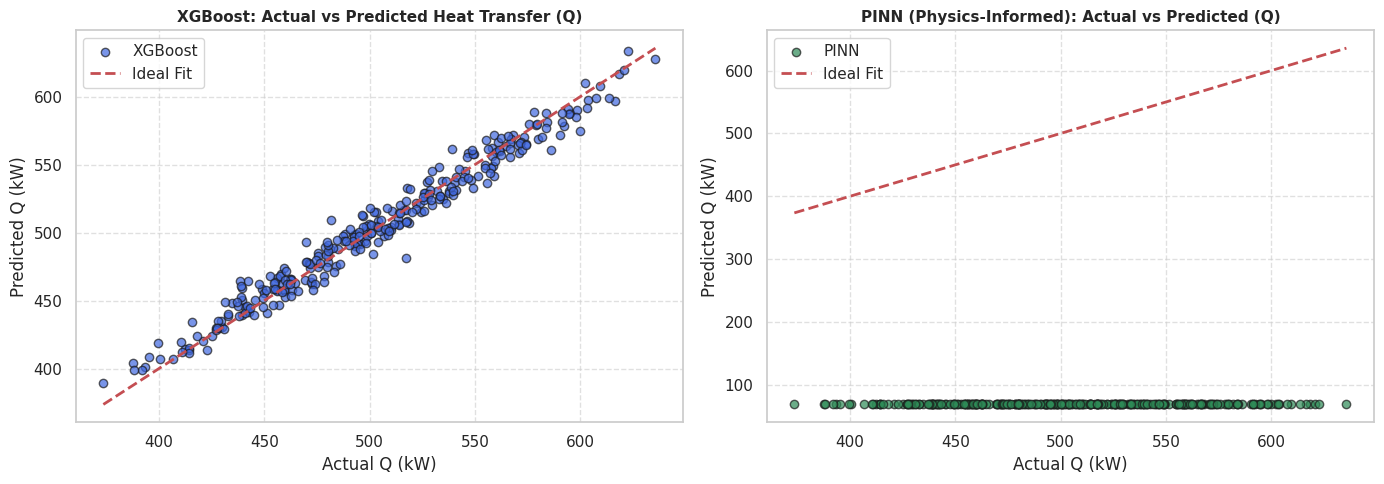

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 5))

# XGBoost: actual vs. predicted
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_xgb, alpha=0.7, color='royalblue', edgecolor='k', label='XGBoost')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
plt.title('XGBoost: Actual vs Predicted Heat Transfer (Q)', fontsize=11, fontweight='bold')
plt.xlabel('Actual Q (kW)')
plt.ylabel('Predicted Q (kW)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# PINN: actual vs. predicted
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_pinn, alpha=0.7, color='seagreen', edgecolor='k', label='PINN')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
plt.title('PINN (Physics-Informed): Actual vs Predicted (Q)', fontsize=11, fontweight='bold')
plt.xlabel('Actual Q (kW)')
plt.ylabel('Predicted Q (kW)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

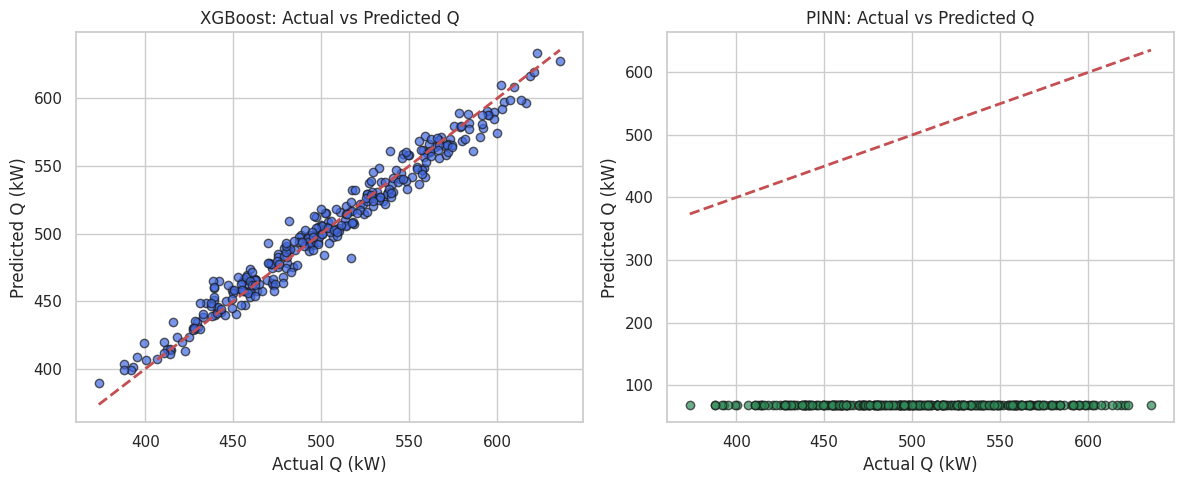

Graph saved successfully as 'actual_vs_predicted.png'!


In [16]:
# Create and save the actual-versus-predicted figure
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_xgb, alpha=0.7, color='royalblue', edgecolor='k', label='XGBoost')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('XGBoost: Actual vs Predicted Q')
plt.xlabel('Actual Q (kW)')
plt.ylabel('Predicted Q (kW)')

plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_pinn, alpha=0.7, color='seagreen', edgecolor='k', label='PINN')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('PINN: Actual vs Predicted Q')
plt.xlabel('Actual Q (kW)')
plt.ylabel('Predicted Q (kW)')

plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=300, bbox_inches='tight')
plt.show()

print("Graph saved successfully as 'actual_vs_predicted.png'!")

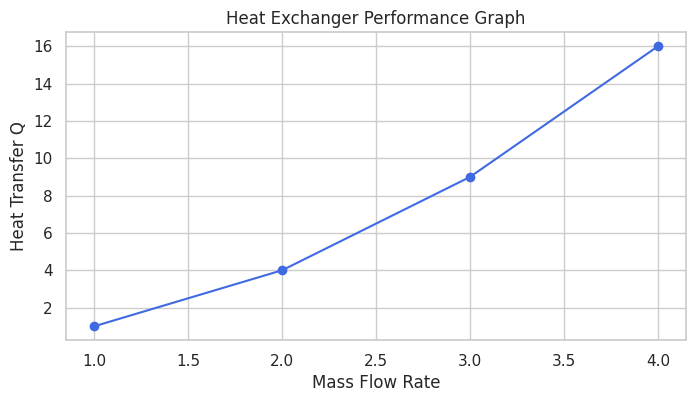

Graph saved as 'heat_exchanger_performance.png'. Download it from the Deepnote file explorer.


In [18]:
# Create and save the example heat-exchanger performance chart
plt.figure(figsize=(8, 4))
plt.plot([1, 2, 3, 4], [1, 4, 9, 16], marker='o', color='royalblue')
plt.title('Heat Exchanger Performance Graph')
plt.xlabel('Mass Flow Rate')
plt.ylabel('Heat Transfer Q')
plt.grid(True)

file_name = 'heat_exchanger_performance.png'
plt.savefig(file_name, dpi=300, bbox_inches='tight')
plt.show()

print(f"Graph saved as '{file_name}'. Download it from the Deepnote file explorer.")

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=df90de21-0ba4-4d02-b630-b8f0b578dbce' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>